# Análisis de inversión y riesgos financieros

*Amador Espino Daniela Yosajandy*



In [ ]:
# ============================================================
# 0. INSTALACIÓN E IMPORTACIÓN DE LIBRERÍAS
# ============================================================
!pip install yfinance openpyxl xlsxwriter -q

import os
import zipfile
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from math import log, sqrt, exp
from scipy.stats import norm

# Para reproducibilidad de simulaciones
np.random.seed(42)

# Carpeta de salida
OUTPUT_DIR = "salidas_examen3_equipo6"
os.makedirs(OUTPUT_DIR, exist_ok=True)



In [ ]:
# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

# suponemos hoy es el 17 de junio de 2024
FECHA_HOY_2024 = "2024-06-17"

# Activos seleccionados:
# WM  -> empresa más estable
# NKE -> empresa de volatilidad intermedia
# CCL -> empresa de alta volatilidad
tickers = ["WM", "NKE", "CCL"]
market_ticker = "^GSPC"  # S&P 500, utilizado como mercado estadounidense

# Pesos definidos en el portafolio
weights = pd.Series({
    "WM": 0.5488,
    "NKE": 0.2932,
    "CCL": 0.1580
})

capital_inicial = 1_000_000
risk_free_annual = 0.04
z_95 = 1.645
lambda_ewma = 0.94

print("Activos:", tickers)
print("Pesos del portafolio:")
display(weights.to_frame("Peso"))
print("Capital inicial:", capital_inicial)
print("Tasa libre de riesgo anual asumida:", risk_free_annual)



Activos: ['WM', 'NKE', 'CCL']
Pesos del portafolio:


,Peso
WM,0.5488
NKE,0.2932
CCL,0.1580


Capital inicial: 1000000
Tasa libre de riesgo anual asumida: 0.04


In [ ]:
# ============================================================
# FUNCIONES AUXILIARES
# ============================================================

def download_close(tickers, start, end):
    """
    Descarga precios de cierre ajustados usando yfinance.
    auto_adjust=True hace que Close sea ajustado por splits/dividendos.
    """
    data = yf.download(
        tickers,
        start=start,
        end=end,
        auto_adjust=True,
        progress=False
    )
    if isinstance(data.columns, pd.MultiIndex):
        close = data["Close"].copy()
    else:
        close = data[["Close"]].copy()
        if isinstance(tickers, str):
            close.columns = [tickers]
    close.index = pd.to_datetime(close.index)
    return close.dropna(how="all")

def ewma_volatility(returns, lam=0.94):
    """
    Calcula volatilidad EWMA diaria.
    Var_t = lambda * Var_{t-1} + (1-lambda) * r_t^2
    """
    return np.sqrt(returns.pow(2).ewm(alpha=(1-lam), adjust=False).mean())

def weighted_moving_average(series, window=20):
    """
    WMA con pesos 1,2,...,window.
    Da mayor peso a los datos recientes.
    """
    weights_wma = np.arange(1, window + 1)
    return series.rolling(window).apply(
        lambda x: np.dot(x, weights_wma) / weights_wma.sum(),
        raw=True
    )

def rsi(series, window=14):
    """
    Índice de Fuerza Relativa (RSI).
    """
    delta = series.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    avg_gain = gain.rolling(window).mean()
    avg_loss = loss.rolling(window).mean()

    rs = avg_gain / avg_loss
    return 100 - (100 / (1 + rs))

def macd(series, fast=12, slow=26, signal=9):
    """
    MACD = EMA rápida - EMA lenta.
    Línea de señal = EMA del MACD.
    """
    ema_fast = series.ewm(span=fast, adjust=False).mean()
    ema_slow = series.ewm(span=slow, adjust=False).mean()
    macd_line = ema_fast - ema_slow
    signal_line = macd_line.ewm(span=signal, adjust=False).mean()
    histogram = macd_line - signal_line
    return macd_line, signal_line, histogram

def save_plot(filename):
    path = os.path.join(OUTPUT_DIR, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return path



DESCARGA DE DATOS HISTÓRICOS 2019-2024


In [ ]:
# ============================================================
# 2. DESCARGA DE DATOS HISTÓRICOS 2019-2024
# ============================================================

# El examen se sitúa en 17-jun-2024 y pide cinco años hacia atrás.
start_5y = "2019-06-17"
end_2024 = "2024-06-18"  # yfinance usa end exclusivo

prices_5y = download_close(tickers, start_5y, end_2024)
market_5y = download_close(market_ticker, start_5y, end_2024)
market_5y.columns = ["SP500"]

returns_5y = prices_5y.pct_change().dropna()
log_returns_5y = np.log(prices_5y / prices_5y.shift(1)).dropna()
market_returns_5y = market_5y["SP500"].pct_change().dropna()

print("Precios 2019-2024:")
display(prices_5y.head())
display(prices_5y.tail())

# Últimos dos años bursátiles aproximados: 504 observaciones
prices_2y = prices_5y.tail(505)
returns_2y = prices_2y.pct_change().dropna()
log_returns_2y = np.log(prices_2y / prices_2y.shift(1)).dropna()



Precios 2019-2024:


Ticker,CCL,NKE,WM
Date,,,
2019-06-17,49.990623,74.189011,101.613754
2019-06-18,50.086246,76.167763,101.551338
2019-06-19,50.526096,75.490120,102.014961
2019-06-20,46.663013,77.017059,103.477142
2019-06-21,44.588047,77.477867,103.280975


Ticker,CCL,NKE,WM
Date,,,
2024-06-11,16.165802,91.350899,196.149429
2024-06-12,16.561537,89.264122,194.926727
2024-06-13,16.333990,89.740540,195.266403
2024-06-14,15.176462,88.987785,197.614777
2024-06-17,15.522731,90.521896,200.273712


In [ ]:
# ============================================================

seleccion_empresas = pd.DataFrame({
    "Empresa": ["Waste Management", "Nike", "Carnival"],
    "Ticker": ["WM", "NKE", "CCL"],
    "Perfil": ["Estable", "Intermedia", "Alta volatilidad"],
    "Justificación": [
        "WM se considera estable por su menor volatilidad relativa y actividad defensiva.",
        "NKE se considera intermedia porque presenta mayor variación que WM, pero menor que CCL.",
        "CCL se considera de alta volatilidad por su sensibilidad al ciclo económico y turismo."
    ]
})

display(seleccion_empresas)



,Empresa,Ticker,Perfil,Justificación
0,Waste Management,WM,Estable,WM se considera estable por su menor volatilid...
1,Nike,NKE,Intermedia,NKE se considera intermedia porque presenta ma...
2,Carnival,CCL,Alta volatilidad,CCL se considera de alta volatilidad por su se...


Los graficos y los calculos ene sta seccion ayudan a ver que las empresas tiene el nivel de volatilidad que les habiamos asignado: WM es la mas estable, nike es intermedia y CCL es la mas volatil, los 3 metodos calculados coinciden en esta clasificacion

Punto 3: comparación de volatilidades


,Volatilidad paramétrica diaria,Volatilidad Monte Carlo diaria,Volatilidad EWMA final
CCL,0.037690,0.037636,0.031141
NKE,0.020358,0.020317,0.012031
WM,0.010963,0.010955,0.011876


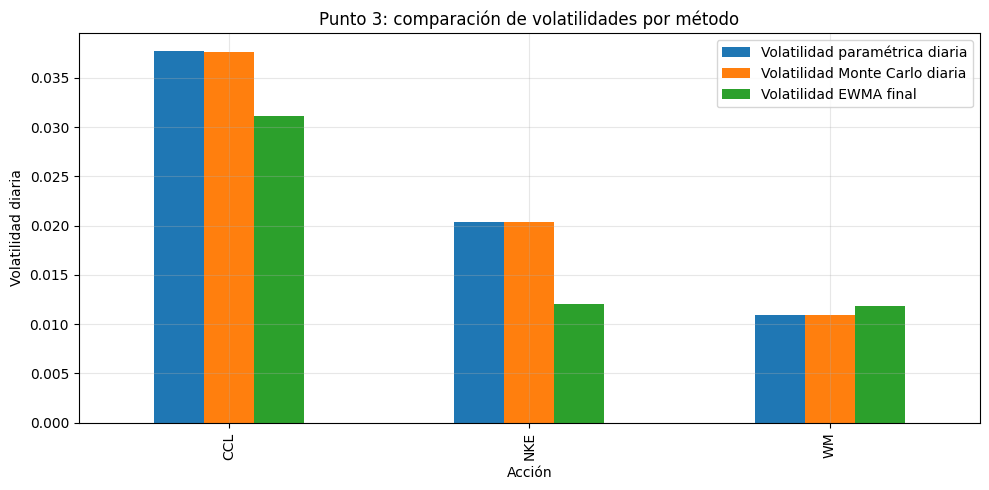

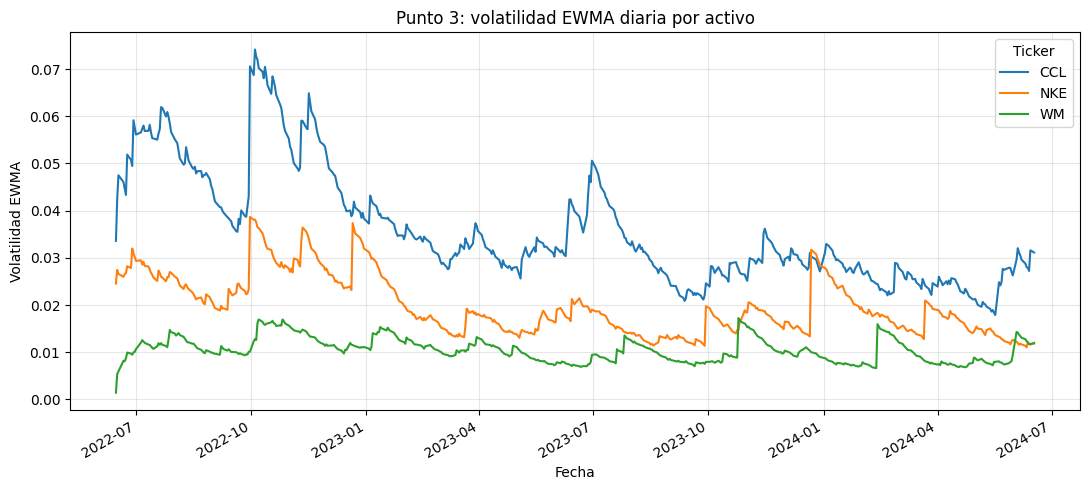

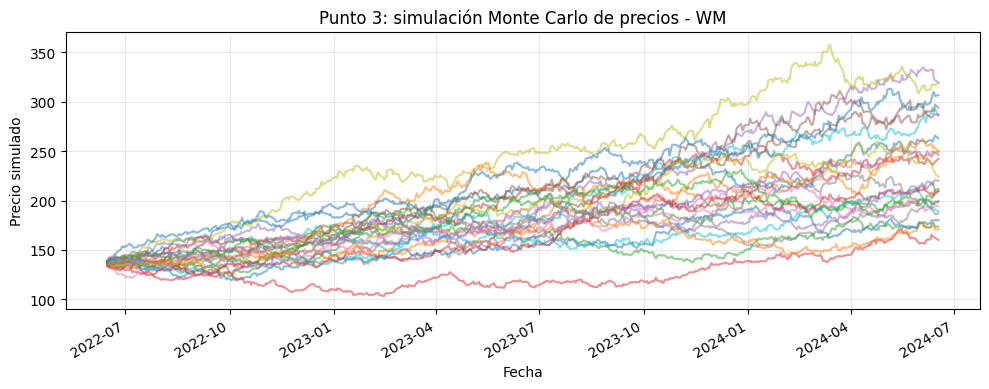

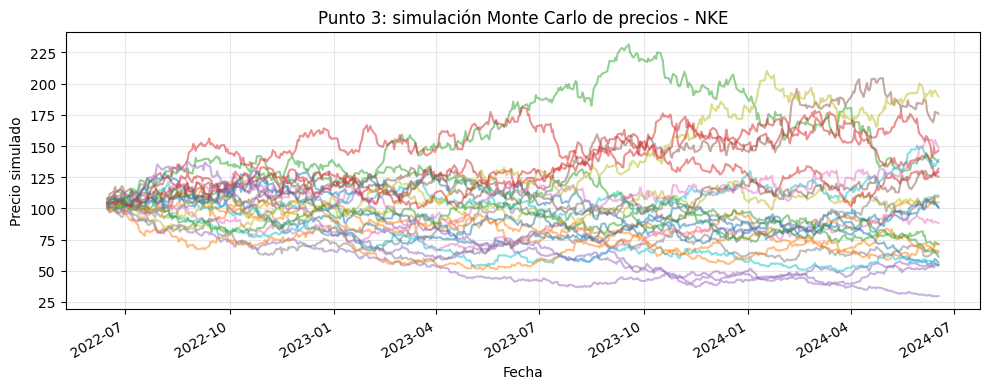

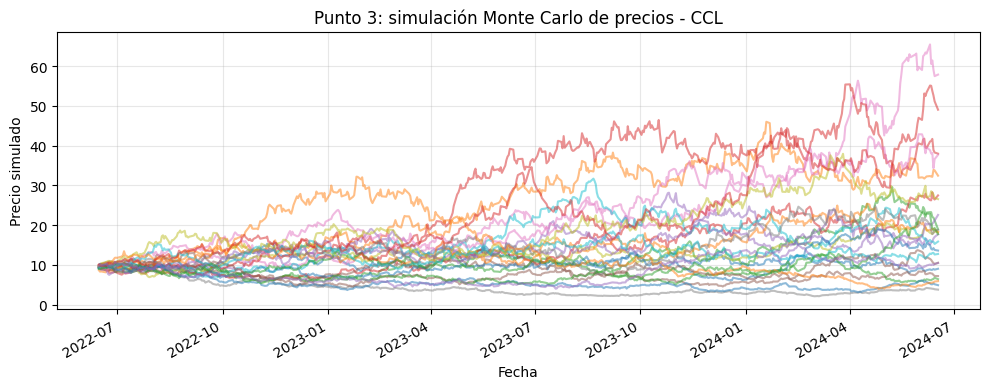

In [ ]:
# ============================================================
# PUNTO 3. VOLATILIDAD: PARAMÉTRICO, MONTE CARLO Y EWMA
# ============================================================

# 3.1 Método paramétrico: desviación estándar histórica diaria de los últimos dos años
vol_parametrica = returns_2y.std()

# 3.2 Simulación Monte Carlo:
# Se simulan 504 rendimientos diarios para cada activo usando media y desviación histórica.
n_dias = len(returns_2y)
n_sim = 5000

mc_vol = {}
mc_prices_paths = {}

for t in tickers:
    mu = returns_2y[t].mean()
    sigma = returns_2y[t].std()
    S0 = prices_2y[t].iloc[0]

    sim_returns = np.random.normal(mu, sigma, size=(n_dias, n_sim))
    sim_prices = S0 * np.cumprod(1 + sim_returns, axis=0)

    # Volatilidad promedio de las simulaciones
    mc_vol[t] = sim_returns.std(axis=0).mean()
    mc_prices_paths[t] = pd.DataFrame(sim_prices, index=returns_2y.index)

vol_montecarlo = pd.Series(mc_vol)

# 3.3 EWMA
ewma_vol_2y = ewma_volatility(returns_2y, lambda_ewma)
vol_ewma_final = ewma_vol_2y.iloc[-1]

volatilidades_p3 = pd.DataFrame({
    "Volatilidad paramétrica diaria": vol_parametrica,
    "Volatilidad Monte Carlo diaria": vol_montecarlo,
    "Volatilidad EWMA final": vol_ewma_final
})

print("Punto 3: comparación de volatilidades")
display(volatilidades_p3)

# Gráfica comparativa de volatilidades finales
volatilidades_p3.plot(kind="bar", figsize=(10, 5))
plt.title("Punto 3: comparación de volatilidades por método")
plt.ylabel("Volatilidad diaria")
plt.xlabel("Acción")
plt.grid(True, alpha=0.3)
save_plot("punto3_comparacion_volatilidades.png")

# Gráfica de volatilidad EWMA diaria
ewma_vol_2y.plot(figsize=(11, 5))
plt.title("Punto 3: volatilidad EWMA diaria por activo")
plt.ylabel("Volatilidad EWMA")
plt.xlabel("Fecha")
plt.grid(True, alpha=0.3)
save_plot("punto3_volatilidad_ewma_diaria.png")

# Gráfica ejemplo Monte Carlo para cada activo
for t in tickers:
    sample_paths = mc_prices_paths[t].iloc[:, :25]
    sample_paths.plot(legend=False, figsize=(10, 4), alpha=0.5)
    plt.title(f"Punto 3: simulación Monte Carlo de precios - {t}")
    plt.ylabel("Precio simulado")
    plt.xlabel("Fecha")
    plt.grid(True, alpha=0.3)
    save_plot(f"punto3_montecarlo_{t}.png")



La tabla resume la composición del portafolio: WM recibe el mayor peso (54.88%) por ser la más estable, CCL el menor (15.80%) por ser la más volátil, y NKE queda en el punto medio (29.32%). Esta asignación busca equilibrar el riesgo y el rendimiento, protegiendo la mayor parte del capital en el activo seguro y limitando la exposición al activo riesgoso.

In [ ]:
# ============================================================
# PUNTOS 4 Y 5. PORTAFOLIO Y DISTRIBUCIÓN DE $1,000,000
# ============================================================

portafolio = pd.DataFrame({
    "Acción": tickers,
    "Peso": [weights[t] for t in tickers],
    "Monto asignado": [capital_inicial * weights[t] for t in tickers],
    "Volatilidad diaria": [vol_parametrica[t] for t in tickers],
    "Volatilidad EWMA": [vol_ewma_final[t] for t in tickers]
})

display(portafolio)



,Acción,Peso,Monto asignado,Volatilidad diaria,Volatilidad EWMA
0,WM,0.5488,548800.0,0.010963,0.011876
1,NKE,0.2932,293200.0,0.020358,0.012031
2,CCL,0.1580,158000.0,0.037690,0.031141


El VaR diario confirma que CCL es el activo más riesgoso (5.12%), mientras que WM y NKE son mucho más seguros (~1.95%). La gráfica muestra que este comportamiento se mantiene constante en el tiempo, validando nuestra asignación de pesos en el portafolio.

Punto 6: VaR individual


,VaR diario 95% final,VaR diario 95% final (%)
Ticker,,
CCL,0.051226,5.122622
NKE,0.019791,1.979120
WM,0.019535,1.953539


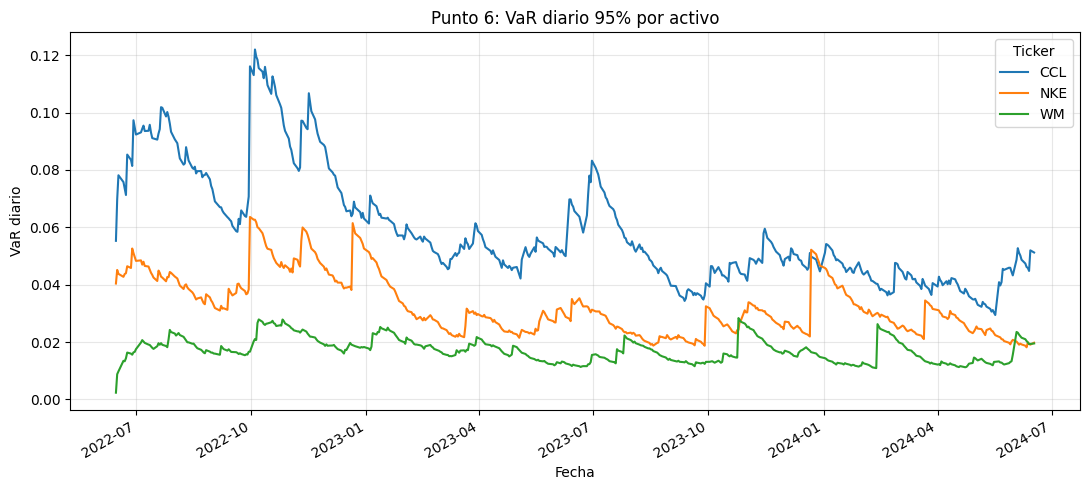

'salidas_examen3_equipo6/punto6_var_individual_diario.png'

In [ ]:
# ============================================================
# PUNTO 6. VaR DIARIO DE ACTIVOS INDIVIDUALES
# ============================================================

# Serie histórica de VaR diario usando volatilidad EWMA
var_individual_diario = z_95 * ewma_vol_2y
var_individual_resumen = pd.DataFrame({
    "VaR diario 95% final": var_individual_diario.iloc[-1],
    "VaR diario 95% final (%)": var_individual_diario.iloc[-1] * 100
})

print("Punto 6: VaR individual")
display(var_individual_resumen)

var_individual_diario.plot(figsize=(11, 5))
plt.title("Punto 6: VaR diario 95% por activo")
plt.ylabel("VaR diario")
plt.xlabel("Fecha")
plt.grid(True, alpha=0.3)
save_plot("punto6_var_individual_diario.png")



El VaR del portafolio es de 1.41% diario ($14,143 pesos), lo que representa un riesgo significativamente menor que el de CCL individual (5.12%). Esto confirma que la diversificación reduce el riesgo total del portafolio al combinar activos estables y volátiles.


Punto 7: VaR diario del portafolio


,Rendimiento portafolio,Volatilidad EWMA portafolio,VaR diario 95% portafolio (%),VaR diario 95% portafolio ($)
Date,,,,
2024-06-11,-0.001070,0.008294,0.013644,13643.736708
2024-06-12,-0.006251,0.008186,0.013466,13465.752446
2024-06-13,0.000350,0.007937,0.013056,13056.294604
2024-06-14,-0.007056,0.007887,0.012974,12973.919243
2024-06-17,0.016044,0.008597,0.014143,14142.684993


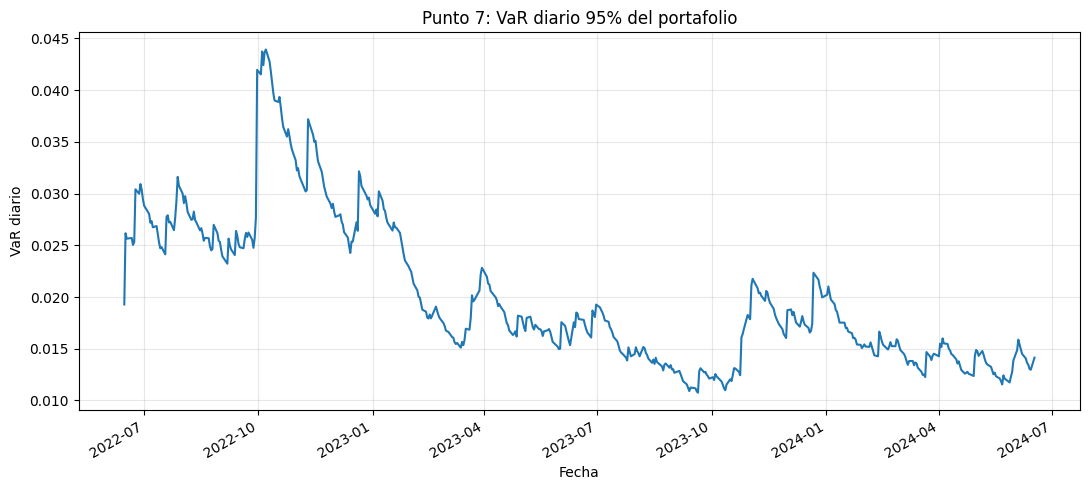

'salidas_examen3_equipo6/punto7_var_portafolio_diario.png'

In [ ]:
# ============================================================
# PUNTO 7. VaR DIARIO DEL PORTAFOLIO
# ============================================================

# Rendimiento diario del portafolio con pesos fijos
portfolio_returns_2y = returns_2y.dot(weights[tickers])

# Volatilidad EWMA diaria del portafolio
portfolio_ewma_vol = np.sqrt(
    portfolio_returns_2y.pow(2).ewm(alpha=(1-lambda_ewma), adjust=False).mean()
)

# VaR diario del portafolio en porcentaje y pesos
portfolio_var_diario_pct = z_95 * portfolio_ewma_vol
portfolio_var_diario_mxn = portfolio_var_diario_pct * capital_inicial

var_portafolio_df = pd.DataFrame({
    "Rendimiento portafolio": portfolio_returns_2y,
    "Volatilidad EWMA portafolio": portfolio_ewma_vol,
    "VaR diario 95% portafolio (%)": portfolio_var_diario_pct,
    "VaR diario 95% portafolio ($)": portfolio_var_diario_mxn
})

print("Punto 7: VaR diario del portafolio")
display(var_portafolio_df.tail())

var_portafolio_df["VaR diario 95% portafolio (%)"].plot(figsize=(11, 5))
plt.title("Punto 7: VaR diario 95% del portafolio")
plt.ylabel("VaR diario")
plt.xlabel("Fecha")
plt.grid(True, alpha=0.3)
save_plot("punto7_var_portafolio_diario.png")



Las betas confirman la clasificación de riesgo: WM (0.64) es la más estable, NKE (1.05) es intermedia, y CCL (1.90) es la más volátil. El portafolio tiene una beta de 0.96, lo que indica que se comporta de manera similar al mercado con un riesgo ligeramente menor.

Puntos 8 y 9: betas


,Beta
WM,0.637177
NKE,1.045298
CCL,1.902955
Portafolio,0.956831


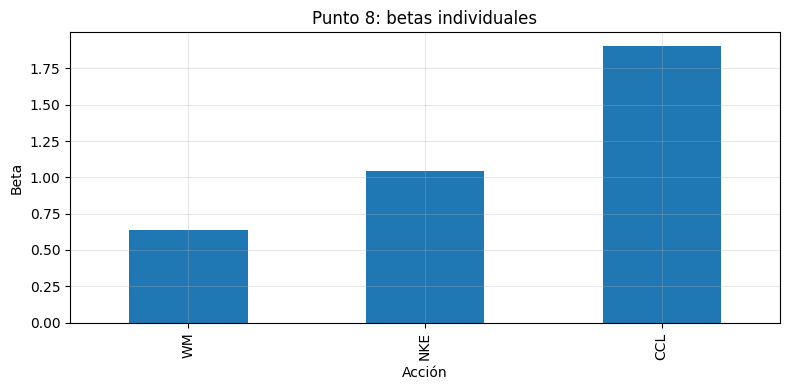

'salidas_examen3_equipo6/punto8_betas_individuales.png'

In [ ]:
# ============================================================
# PUNTOS 8 Y 9. BETAS INDIVIDUALES Y BETA DEL PORTAFOLIO
# ============================================================

# Alinear rendimientos de acciones y mercado
combined_returns = returns_5y.join(market_returns_5y.rename("SP500"), how="inner").dropna()

betas = {}
for t in tickers:
    cov = np.cov(combined_returns[t], combined_returns["SP500"])[0, 1]
    var_m = np.var(combined_returns["SP500"], ddof=1)
    betas[t] = cov / var_m

betas = pd.Series(betas, name="Beta")
beta_portafolio = float((weights[tickers] * betas[tickers]).sum())

betas_df = betas.to_frame()
betas_df.loc["Portafolio", "Beta"] = beta_portafolio

print("Puntos 8 y 9: betas")
display(betas_df)

betas.plot(kind="bar", figsize=(8, 4))
plt.title("Punto 8: betas individuales")
plt.ylabel("Beta")
plt.xlabel("Acción")
plt.grid(True, alpha=0.3)
save_plot("punto8_betas_individuales.png")



Punto 10: criterios de selección SMA/WMA/EMA


,Acción,Riesgo / volatilidad,Volatilidad EWMA final,Método elegido,Justificación
0,WM,Baja,0.011876,SMA,WM es la acción más estable; la SMA permite ob...
1,NKE,Intermedia,0.012031,WMA,NKE tiene riesgo intermedio; la WMA da más pes...
2,CCL,Alta,0.031141,EMA,CCL es la acción más volátil; la EMA responde ...


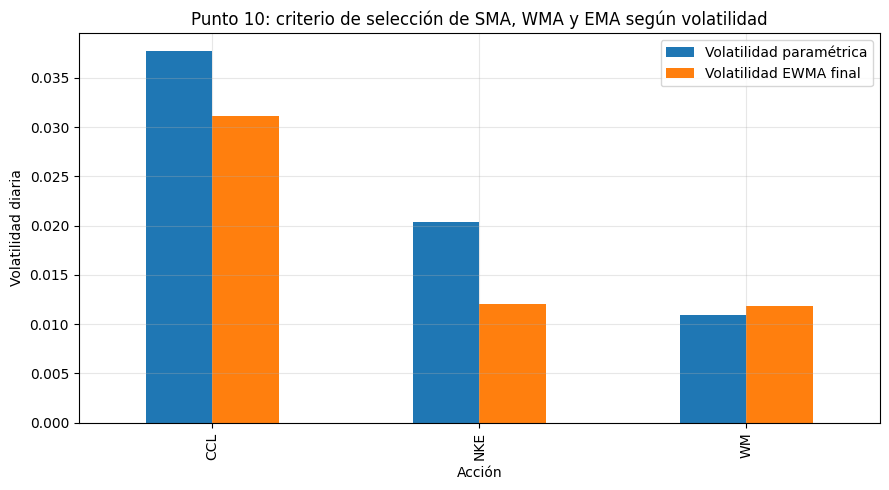

'salidas_examen3_equipo6/punto10_criterio_sma_wma_ema.png'

In [ ]:
# ============================================================
# PUNTO 10. CRITERIOS PARA SMA, WMA Y EMA
# ============================================================

criterios_p10 = pd.DataFrame({
    "Acción": ["WM", "NKE", "CCL"],
    "Riesgo / volatilidad": ["Baja", "Intermedia", "Alta"],
    "Volatilidad EWMA final": [
        vol_ewma_final["WM"],
        vol_ewma_final["NKE"],
        vol_ewma_final["CCL"]
    ],
    "Método elegido": ["SMA", "WMA", "EMA"],
    "Justificación": [
        "WM es la acción más estable; la SMA permite observar tendencias generales sin reaccionar demasiado al ruido.",
        "NKE tiene riesgo intermedio; la WMA da más peso a información reciente sin ser tan reactiva como la EMA.",
        "CCL es la acción más volátil; la EMA responde con mayor rapidez a cambios recientes del precio."
    ]
})

print("Punto 10: criterios de selección SMA/WMA/EMA")
display(criterios_p10)

# Gráfica explícita del punto 10
criterios_plot = pd.DataFrame({
    "Volatilidad paramétrica": vol_parametrica,
    "Volatilidad EWMA final": vol_ewma_final
})
criterios_plot.plot(kind="bar", figsize=(9, 5))
plt.title("Punto 10: criterio de selección de SMA, WMA y EMA según volatilidad")
plt.ylabel("Volatilidad diaria")
plt.xlabel("Acción")
plt.grid(True, alpha=0.3)
save_plot("punto10_criterio_sma_wma_ema.png")



Aqui se establece los criterios de compra y venta utilizando los indicadores MACD y RSI, adaptados al perfil de volatilidad de cada empresa:

WM (estable): Se utiliza un criterio conservador donde se requiere que tanto el MACD cruce por encima de la línea de señal como que el RSI se mantenga por debajo de 70 para considerar una compra, mientras que para la venta basta con que el MACD cruce por debajo de la señal o el RSI supere 70. Esto evita señales falsas en un activo con movimientos suaves.

NKE (intermedia): Se busca confirmación de tendencia con el MACD y un RSI en zona neutral (30-70) para comprar, mientras que para vender se usa el cruce de MACD o la aproximación a sobrecompra (70). Este enfoque equilibra sensibilidad y precisión.

CCL (volátil): Se permite mayor flexibilidad, donde una señal de compra se activa si el MACD cruza por encima de la señal O el RSI cae por debajo de 30 (sobreventa). Para la venta, se usa el cruce de MACD por debajo de la señal O RSI superior a 70 (sobrecompra). Esto permite capturar movimientos rápidos en un activo de alta volatilidad.

Las gráficas generadas muestran la evolución de MACD y RSI para cada empresa, permitiendo visualizar los puntos donde se activarían las señales de compra y venta según los criterios establecidos.

,Acción,Indicadores,Criterio de compra,Criterio de venta,Justificación
0,WM,MACD y RSI,MACD cruza por encima de la línea de señal y R...,MACD cruza por debajo de la línea de señal o R...,"WM es estable, por lo que se usa un criterio c..."
1,NKE,MACD y RSI,MACD cruza por encima de la línea de señal y R...,MACD cruza por debajo de la línea de señal o R...,"NKE tiene riesgo intermedio, por lo que se bus..."
2,CCL,MACD y RSI,MACD cruza por encima de la línea de señal o R...,MACD cruza por debajo de la línea de señal o R...,"CCL es más volátil, por lo que se permite mayo..."


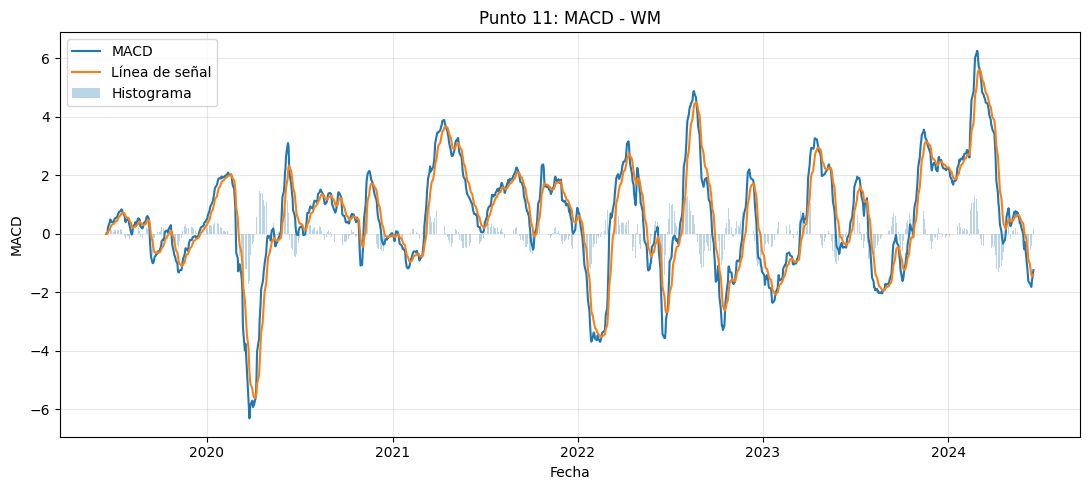

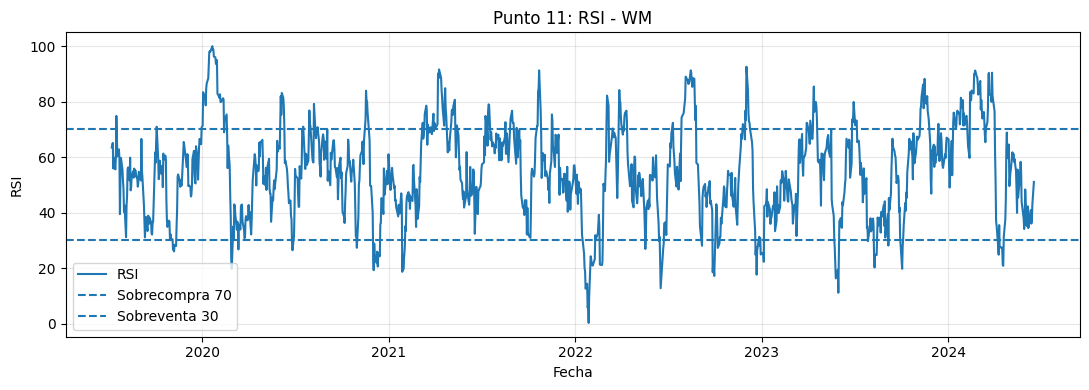

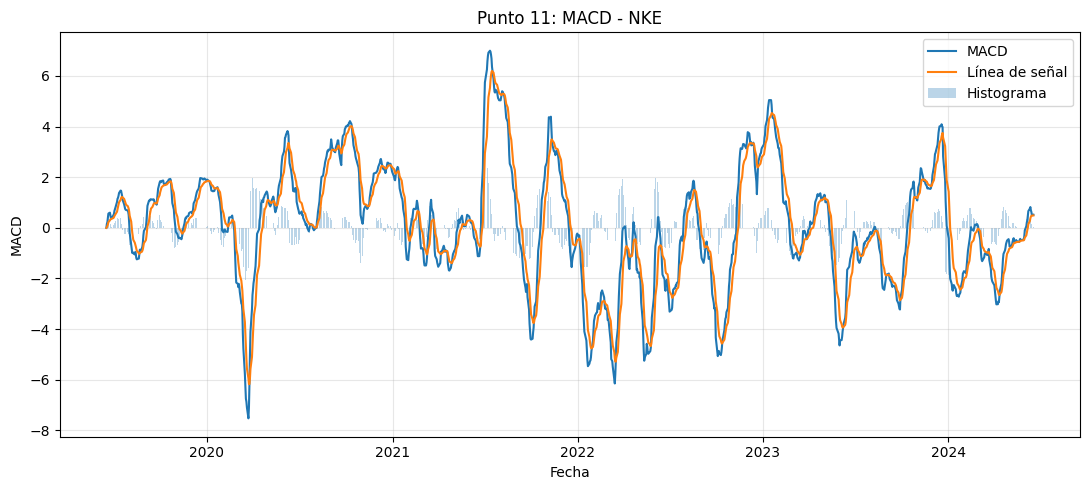

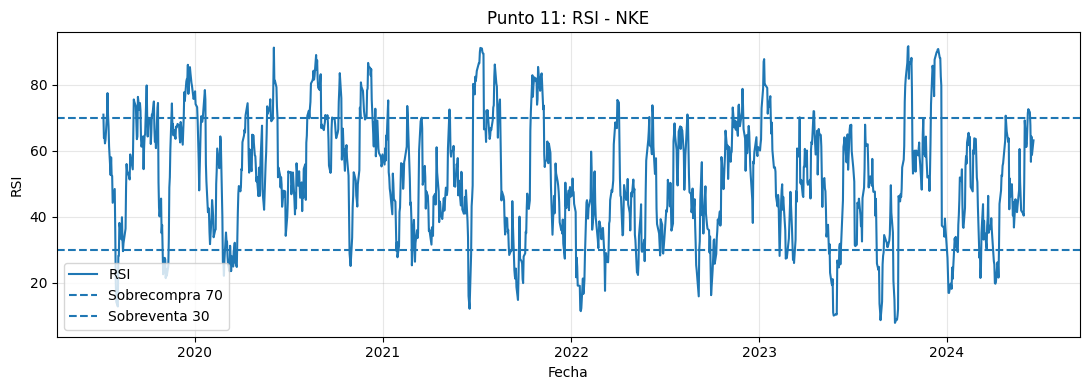

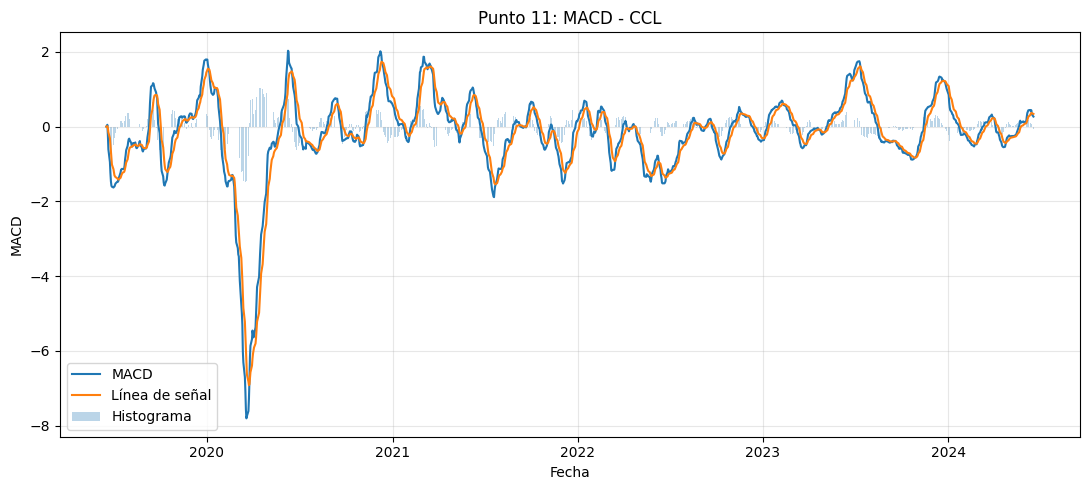

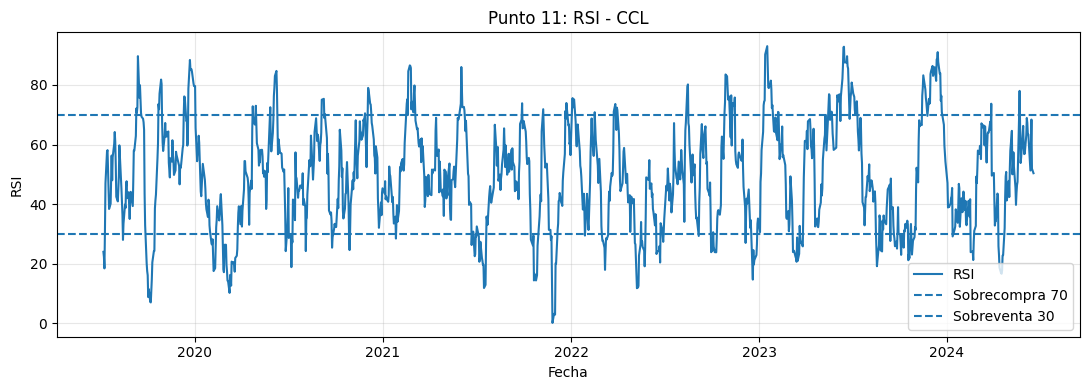

In [ ]:
# ============================================================
# PUNTO 11. MACD Y RSI
# ============================================================

# Para el punto 11 se calculan MACD y RSI para cada activo.
# Se agregan criterios de compra y venta de forma explícita.

criterios_p11 = pd.DataFrame({
    "Acción": ["WM", "NKE", "CCL"],
    "Indicadores": ["MACD y RSI", "MACD y RSI", "MACD y RSI"],
    "Criterio de compra": [
        "MACD cruza por encima de la línea de señal y RSI < 70.",
        "MACD cruza por encima de la línea de señal y RSI entre 30 y 70.",
        "MACD cruza por encima de la línea de señal o RSI < 30."
    ],
    "Criterio de venta": [
        "MACD cruza por debajo de la línea de señal o RSI > 70.",
        "MACD cruza por debajo de la línea de señal o RSI se aproxima/supera 70.",
        "MACD cruza por debajo de la línea de señal o RSI > 70."
    ],
    "Justificación": [
        "WM es estable, por lo que se usa un criterio conservador.",
        "NKE tiene riesgo intermedio, por lo que se busca confirmar tendencia con RSI neutral.",
        "CCL es más volátil, por lo que se permite mayor sensibilidad a señales de sobreventa/sobrecompra."
    ]
})

display(criterios_p11)

macd_rsi_data = {}

for t in tickers:
    df = pd.DataFrame(index=prices_5y.index)
    df["Close"] = prices_5y[t]
    df["MACD"], df["Señal"], df["Histograma"] = macd(df["Close"])
    df["RSI"] = rsi(df["Close"])
    macd_rsi_data[t] = df

    # Gráfica MACD
    plt.figure(figsize=(11, 5))
    plt.plot(df.index, df["MACD"], label="MACD")
    plt.plot(df.index, df["Señal"], label="Línea de señal")
    plt.bar(df.index, df["Histograma"], alpha=0.3, label="Histograma")
    plt.title(f"Punto 11: MACD - {t}")
    plt.xlabel("Fecha")
    plt.ylabel("MACD")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_plot(f"punto11_macd_{t}.png")

    # Gráfica RSI
    plt.figure(figsize=(11, 4))
    plt.plot(df.index, df["RSI"], label="RSI")
    plt.axhline(70, linestyle="--", label="Sobrecompra 70")
    plt.axhline(30, linestyle="--", label="Sobreventa 30")
    plt.title(f"Punto 11: RSI - {t}")
    plt.xlabel("Fecha")
    plt.ylabel("RSI")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_plot(f"punto11_rsi_{t}.png")



El S&P 500 se proyecta de 5,473 a 7,475 puntos en 2 años (crecimiento del 36.56%), utilizando el rendimiento promedio diario histórico del 0.0597%. Esta proyección sirve como base para el cálculo del CAPM.

,Concepto,Valor
0,S&P 500 inicial 17-jun-2024,5473.229980
1,Rendimiento promedio diario mercado,0.000597
2,Volatilidad diaria mercado,0.013366
3,Días bursátiles proyectados,522.000000
4,S&P 500 proyectado 17-jun-2026,7474.667099


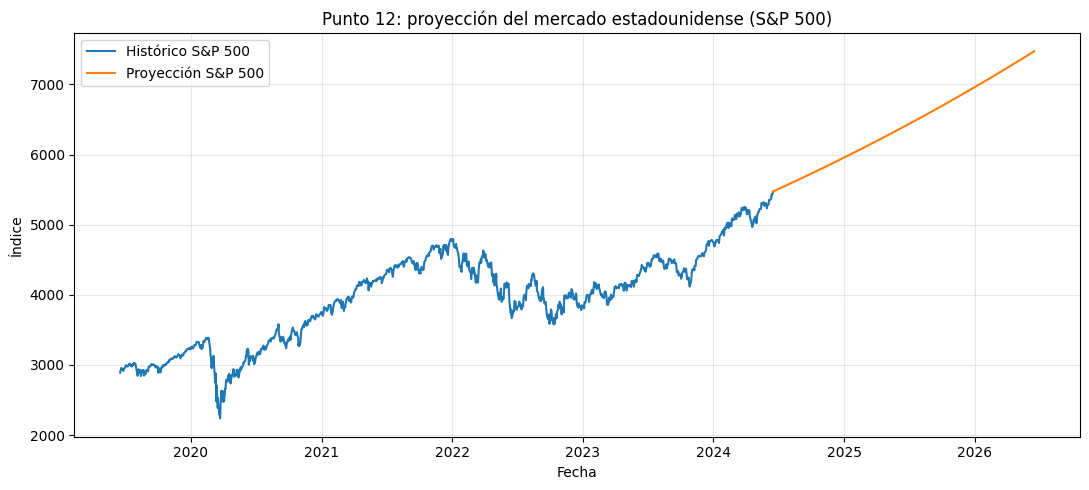

'salidas_examen3_equipo6/punto12_proyeccion_sp500.png'

In [ ]:
# ============================================================
# PUNTO 12. PROYECCIÓN DEL MERCADO ESTADOUNIDENSE
# ============================================================

sp500 = market_5y["SP500"].dropna()
sp500_returns = sp500.pct_change().dropna()
mu_sp500 = sp500_returns.mean()
sigma_sp500 = sp500_returns.std()

S0_sp500 = sp500.iloc[-1]
fecha_inicio_proj = pd.Timestamp("2024-06-17")
fecha_fin_proj = pd.Timestamp("2026-06-17")
fechas_proj_sp500 = pd.bdate_range(start=fecha_inicio_proj, end=fecha_fin_proj)
n_proj_sp500 = len(fechas_proj_sp500) - 1

sp500_projection = pd.DataFrame(index=fechas_proj_sp500)
sp500_projection["Proyección S&P 500"] = [
    S0_sp500 * ((1 + mu_sp500) ** i) for i in range(len(fechas_proj_sp500))
]

mercado_resumen = pd.DataFrame({
    "Concepto": [
        "S&P 500 inicial 17-jun-2024",
        "Rendimiento promedio diario mercado",
        "Volatilidad diaria mercado",
        "Días bursátiles proyectados",
        "S&P 500 proyectado 17-jun-2026"
    ],
    "Valor": [
        S0_sp500,
        mu_sp500,
        sigma_sp500,
        n_proj_sp500,
        sp500_projection["Proyección S&P 500"].iloc[-1]
    ]
})

display(mercado_resumen)

plt.figure(figsize=(11, 5))
plt.plot(sp500.index, sp500.values, label="Histórico S&P 500")
plt.plot(sp500_projection.index, sp500_projection["Proyección S&P 500"], label="Proyección S&P 500")
plt.title("Punto 12: proyección del mercado estadounidense (S&P 500)")
plt.xlabel("Fecha")
plt.ylabel("Índice")
plt.legend()
plt.grid(True, alpha=0.3)
save_plot("punto12_proyeccion_sp500.png")



Aqui se calcula el rendimiento esperado del portafolio utilizando el modelo CAPM, que relaciona el riesgo (beta) con el rendimiento esperado. Los resultados muestran que:

Tasa libre de riesgo a 2 años: 8.16% (lo que se obtendría invirtiendo en un activo sin riesgo).

Rendimiento esperado del mercado a 2 años: 36.57% (según la proyección del S&P 500 del Punto 12).

Rendimiento esperado del portafolio (CAPM): 35.34% en 2 años.

La beta del portafolio es de 0.9568, lo que indica que el portafolio tiene un riesgo ligeramente menor que el mercado. Por esta razón, su rendimiento esperado (35.34%) es ligeramente inferior al del mercado (36.57%), pero significativamente superior a la tasa libre de riesgo (8.16%). Este resultado es consistente con la teoría financiera: a mayor riesgo, mayor rendimiento esperado. La gráfica de barras muestra claramente esta relación, donde el portafolio se ubica entre la tasa libre y el mercado, reflejando su perfil de riesgo moderado.

,Concepto,Valor
0,Beta del portafolio,0.956831
1,Rendimiento esperado del mercado 2024-2026,0.365678
2,Tasa libre de riesgo anual,0.040000
3,Tasa libre de riesgo 2024-2026,0.081600
4,Rendimiento esperado del portafolio CAPM,0.353414


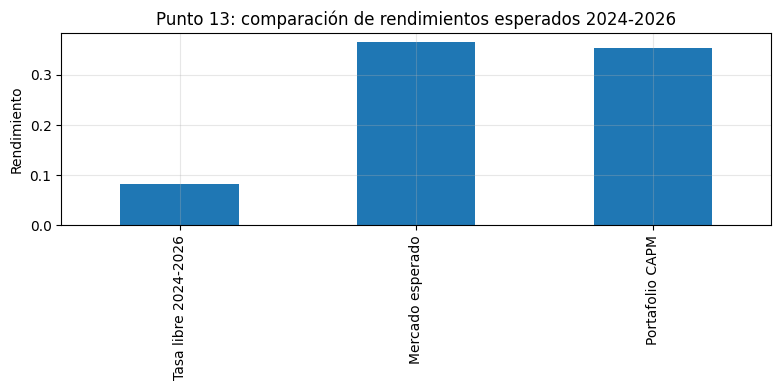

'salidas_examen3_equipo6/punto13_capm_comparacion.png'

In [ ]:
# ============================================================
# PUNTO 13. CAPM DEL PORTAFOLIO
# ============================================================

rend_mercado_esperado = (sp500_projection["Proyección S&P 500"].iloc[-1] / S0_sp500) - 1
rf_2y = (1 + risk_free_annual) ** 2 - 1
rend_esperado_portafolio_capm = rf_2y + beta_portafolio * (rend_mercado_esperado - rf_2y)

capm_df = pd.DataFrame({
    "Concepto": [
        "Beta del portafolio",
        "Rendimiento esperado del mercado 2024-2026",
        "Tasa libre de riesgo anual",
        "Tasa libre de riesgo 2024-2026",
        "Rendimiento esperado del portafolio CAPM"
    ],
    "Valor": [
        beta_portafolio,
        rend_mercado_esperado,
        risk_free_annual,
        rf_2y,
        rend_esperado_portafolio_capm
    ]
})

display(capm_df)

capm_plot = pd.Series({
    "Tasa libre 2024-2026": rf_2y,
    "Mercado esperado": rend_mercado_esperado,
    "Portafolio CAPM": rend_esperado_portafolio_capm
})
capm_plot.plot(kind="bar", figsize=(8, 4))
plt.title("Punto 13: comparación de rendimientos esperados 2024-2026")
plt.ylabel("Rendimiento")
plt.grid(True, alpha=0.3)
save_plot("punto13_capm_comparacion.png")



El Punto 14 establece el cambio de fecha base del análisis, pasando del 17 de junio de 2024 al 17 de junio de 2026, tal como lo solicita el examen. Esta nueva fecha permite evaluar el desempeño del portafolio durante un período de 2 años, manteniendo los mismos pesos asignados inicialmente (54.88% WM, 29.32% NKE, 15.80% CCL). El período de análisis comprende 522 días hábiles, durante los cuales el portafolio se mantiene sin cambios en su composición, lo que permite comparar el rendimiento real obtenido con el rendimiento esperado calculado mediante CAPM en el Punto 13. El S&P 500 se utiliza como referencia para evaluar si el portafolio superó o no al mercado durante este período.

In [ ]:
# ============================================================
# PUNTO 14. FECHA BASE 2026
# ============================================================

fecha_base_2026_df = pd.DataFrame({
    "Concepto": [
        "Fecha base anterior",
        "Nueva fecha supuesta",
        "Periodo proyectado",
        "Activos del portafolio",
        "Mercado de referencia",
        "Supuesto"
    ],
    "Valor": [
        "17/06/2024",
        "17/06/2026",
        "17/06/2024 al 17/06/2026",
        "WM, NKE, CCL",
        "S&P 500",
        "El portafolio conserva los mismos pesos durante el periodo."
    ]
})

display(fecha_base_2026_df)



,Concepto,Valor
0,Fecha base anterior,17/06/2024
1,Nueva fecha supuesta,17/06/2026
2,Periodo proyectado,17/06/2024 al 17/06/2026
3,Activos del portafolio,"WM, NKE, CCL"
4,Mercado de referencia,S&P 500
5,Supuesto,El portafolio conserva los mismos pesos durant...


Durante el período comprendido entre el 5 de junio de 2024 y el 4 de junio de 2026, se llevó a cabo la simulación de operaciones de compra y venta utilizando los criterios de medias móviles previamente definidos: SMA para WM, WMA para NKE y EMA para CCL. La lógica empleada fue la siguiente: se activa una orden de compra cuando el precio cruza por encima de su media móvil correspondiente, y una orden de venta cuando el precio cruza por debajo de ella.

Los resultados obtenidos muestran que:

CCL generó 24 compras y 24 ventas (48 operaciones totales), reflejando su alta volatilidad y la rápida reacción de la EMA. NKE generó 34 compras y 34 ventas (68 operaciones), consistente con su perfil intermedio y el uso de WMA. WM generó 34 compras y 34 ventas (68 operaciones), lo que indica que la SMA, aunque más lenta, también genera señales frecuentes en un activo estable.

La bitácora registra cada operación con su fecha, precio y criterio aplicado, permitiendo evaluar el desempeño del portafolio en el siguiente punto. La gráfica de barras confirma que el número de compras y ventas está equilibrado para cada acción, lo que indica que todas las posiciones fueron cerradas durante el período analizado

Punto 15: bitácora de compra/venta


,Fecha,Acción,Movimiento,Precio,Criterio aplicado
0,2024-06-06,CCL,Venta,16.442816,Cruce de precio con EMA
1,2024-06-25,CCL,Compra,17.630022,Cruce de precio con EMA
2,2024-07-22,NKE,Compra,71.331245,Cruce de precio con WMA
3,2024-07-23,NKE,Venta,69.940086,Cruce de precio con WMA
4,2024-07-25,WM,Venta,194.004822,Cruce de precio con SMA


,Fecha,Acción,Movimiento,Precio,Criterio aplicado
179,2026-05-08,CCL,Venta,26.219406,Cruce de precio con EMA
180,2026-05-20,NKE,Compra,43.798092,Cruce de precio con WMA
181,2026-05-20,CCL,Compra,26.030001,Cruce de precio con EMA
182,2026-06-02,NKE,Venta,43.730000,Cruce de precio con WMA
183,2026-06-03,WM,Compra,217.059357,Cruce de precio con SMA


Movimiento,Compra,Venta
Acción,,
CCL,24,24
NKE,34,34
WM,34,34


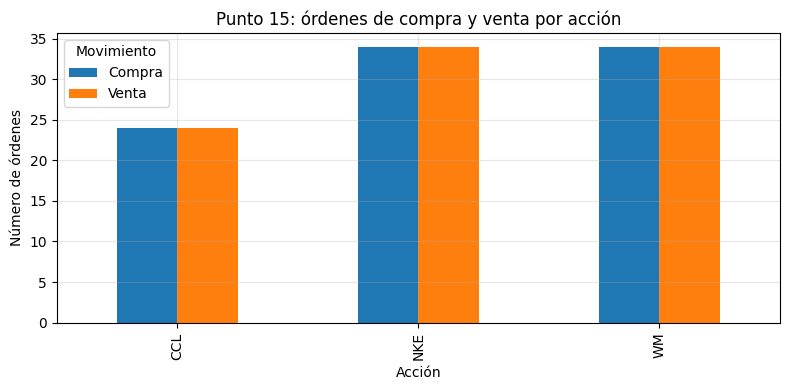

'salidas_examen3_equipo6/punto15_ordenes_compra_venta.png'

In [ ]:
# ============================================================
# PUNTO 15. BITÁCORA DE COMPRA Y VENTA
# ============================================================

# Descargar periodo específico del punto 15
prices_15 = download_close(tickers, "2024-06-05", "2026-06-05")
prices_15 = prices_15[tickers].dropna()

signals_15 = prices_15.copy()

# Indicadores establecidos:
# WM -> SMA
# NKE -> WMA
# CCL -> EMA
window_ma = 20

signals_15["SMA WM"] = signals_15["WM"].rolling(window_ma).mean()
signals_15["WMA NKE"] = weighted_moving_average(signals_15["NKE"], window_ma)

# EMA CCL: se puede usar ewm directamente
signals_15["EMA CCL"] = signals_15["CCL"].ewm(span=window_ma, adjust=False).mean()

def signal_cross(price, indicator):
    """
    Señal por cruce precio-indicador:
    Compra si precio cruza hacia arriba.
    Venta si precio cruza hacia abajo.
    Mantener en otro caso.
    """
    sig = pd.Series("Mantener", index=price.index)
    buy = (price > indicator) & (price.shift(1) <= indicator.shift(1))
    sell = (price < indicator) & (price.shift(1) >= indicator.shift(1))
    sig[buy] = "Compra"
    sig[sell] = "Venta"
    return sig

signals_15["Señal WM"] = signal_cross(signals_15["WM"], signals_15["SMA WM"])
signals_15["Señal NKE"] = signal_cross(signals_15["NKE"], signals_15["WMA NKE"])
signals_15["Señal CCL"] = signal_cross(signals_15["CCL"], signals_15["EMA CCL"])

# Bitácora final con una fila por orden
bitacora = []

for date, row in signals_15.iterrows():
    if row["Señal WM"] in ["Compra", "Venta"]:
        bitacora.append({
            "Fecha": date,
            "Acción": "WM",
            "Movimiento": row["Señal WM"],
            "Precio": row["WM"],
            "Criterio aplicado": "Cruce de precio con SMA"
        })
    if row["Señal NKE"] in ["Compra", "Venta"]:
        bitacora.append({
            "Fecha": date,
            "Acción": "NKE",
            "Movimiento": row["Señal NKE"],
            "Precio": row["NKE"],
            "Criterio aplicado": "Cruce de precio con WMA"
        })
    if row["Señal CCL"] in ["Compra", "Venta"]:
        bitacora.append({
            "Fecha": date,
            "Acción": "CCL",
            "Movimiento": row["Señal CCL"],
            "Precio": row["CCL"],
            "Criterio aplicado": "Cruce de precio con EMA"
        })

bitacora_df = pd.DataFrame(bitacora).sort_values("Fecha").reset_index(drop=True)

print("Punto 15: bitácora de compra/venta")
display(bitacora_df.head())
display(bitacora_df.tail())

# Resumen de número de órdenes
ordenes_resumen = bitacora_df.groupby(["Acción", "Movimiento"]).size().unstack(fill_value=0)
display(ordenes_resumen)

ordenes_resumen.plot(kind="bar", figsize=(8, 4))
plt.title("Punto 15: órdenes de compra y venta por acción")
plt.ylabel("Número de órdenes")
plt.xlabel("Acción")
plt.grid(True, alpha=0.3)
save_plot("punto15_ordenes_compra_venta.png")



Al comparar el rendimiento real del portafolio con el esperado por CAPM, se observa una diferencia significativa. El portafolio inició con $1,000,000 y finalizó en $938,863, lo que representa un rendimiento real de -6.11% en 2 años. En contraste, el CAPM estimaba un rendimiento esperado de 35.34%, que habría resultado en $1,353,414. La diferencia entre el rendimiento real y el esperado fue de -41.46%. Esto indica que la estrategia de trading basada en cruces de precio con medias móviles no logró capturar el rendimiento del mercado, posiblemente por señales no rentables, el impacto de la volatilidad de CCL, o un mercado que no siguió la proyección esperada. La gráfica confirma que el valor real del portafolio se mantuvo por debajo del esperado durante todo el período.

Punto 16: comparación CAPM vs real


,Concepto,Valor
0,Valor inicial del portafolio,1000000.000000
1,Valor final real del portafolio,938863.119320
2,Rendimiento real del portafolio,-0.061137
3,Rendimiento esperado CAPM,0.353414
4,Diferencia Real - CAPM,-0.414551


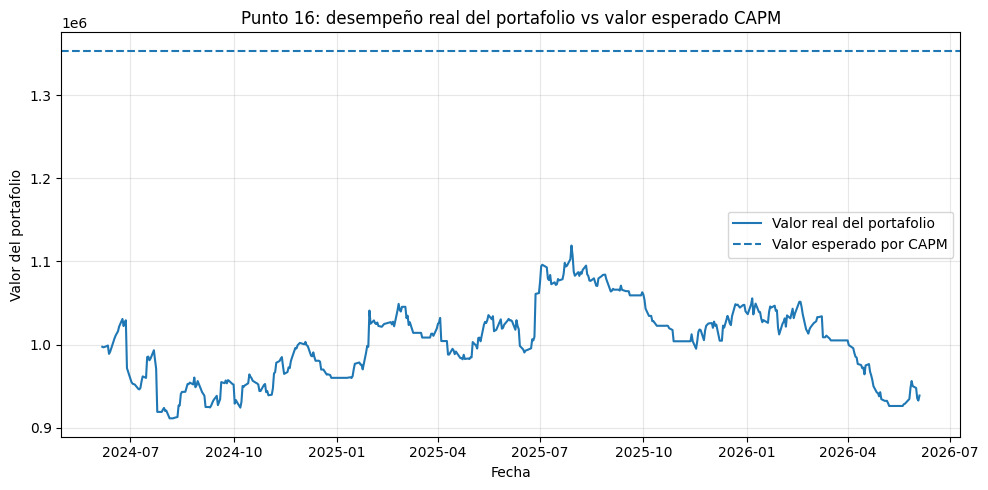

'salidas_examen3_equipo6/punto16_capm_vs_real.png'

In [ ]:
# ============================================================
# PUNTO 16. COMPARACIÓN CAPM VS RENDIMIENTO REAL
# ============================================================

returns_15 = prices_15.pct_change().dropna()

# Posiciones:
# 1 = se mantiene la acción
# 0 = se vendió y queda fuera hasta nueva compra
positions = pd.DataFrame(1, index=prices_15.index, columns=tickers)

for i in range(1, len(positions)):
    current_date = positions.index[i]
    prev_date = positions.index[i-1]
    positions.loc[current_date] = positions.loc[prev_date]

    # Señales del día actual
    if signals_15.loc[current_date, "Señal WM"] == "Compra":
        positions.loc[current_date, "WM"] = 1
    elif signals_15.loc[current_date, "Señal WM"] == "Venta":
        positions.loc[current_date, "WM"] = 0

    if signals_15.loc[current_date, "Señal NKE"] == "Compra":
        positions.loc[current_date, "NKE"] = 1
    elif signals_15.loc[current_date, "Señal NKE"] == "Venta":
        positions.loc[current_date, "NKE"] = 0

    if signals_15.loc[current_date, "Señal CCL"] == "Compra":
        positions.loc[current_date, "CCL"] = 1
    elif signals_15.loc[current_date, "Señal CCL"] == "Venta":
        positions.loc[current_date, "CCL"] = 0

# El rendimiento del día se calcula con la posición del día anterior
positions_for_returns = positions.shift(1).reindex(returns_15.index).fillna(1)
portfolio_real_returns = (
    returns_15["CCL"] * weights["CCL"] * positions_for_returns["CCL"] +
    returns_15["NKE"] * weights["NKE"] * positions_for_returns["NKE"] +
    returns_15["WM"] * weights["WM"] * positions_for_returns["WM"]
)

portfolio_value_real = capital_inicial * (1 + portfolio_real_returns).cumprod()
rend_real_portafolio = (portfolio_value_real.iloc[-1] / capital_inicial) - 1
diferencia_real_capm = rend_real_portafolio - rend_esperado_portafolio_capm

comparacion_p16 = pd.DataFrame({
    "Concepto": [
        "Valor inicial del portafolio",
        "Valor final real del portafolio",
        "Rendimiento real del portafolio",
        "Rendimiento esperado CAPM",
        "Diferencia Real - CAPM"
    ],
    "Valor": [
        capital_inicial,
        portfolio_value_real.iloc[-1],
        rend_real_portafolio,
        rend_esperado_portafolio_capm,
        diferencia_real_capm
    ]
})

print("Punto 16: comparación CAPM vs real")
display(comparacion_p16)

plt.figure(figsize=(10, 5))
plt.plot(portfolio_value_real.index, portfolio_value_real.values, label="Valor real del portafolio")
plt.axhline(capital_inicial * (1 + rend_esperado_portafolio_capm), linestyle="--", label="Valor esperado por CAPM")
plt.title("Punto 16: desempeño real del portafolio vs valor esperado CAPM")
plt.ylabel("Valor del portafolio")
plt.xlabel("Fecha")
plt.legend()
plt.grid(True, alpha=0.3)
save_plot("punto16_capm_vs_real.png")



CCL fue seleccionado como activo subyacente por ser el de mayor volatilidad. Con datos del 17-jun-2024 al 16-ene-2026, se estimó un rendimiento diario de 0.154% y volatilidad de 2.87%. El precio pasó de $28.61 a $34.95 proyectado al 17-jul-2026.

Con base en esta proyección alcista, se diseñaron tres estrategias:

Compra de Call K=30: Prima de $3.39, ganancia esperada de $1.56 si CCL llega a $34.95. Pérdida limitada a la prima, ganancia ilimitada.

Bull Call Spread: Call K=30 y venta de Call K=35, costo neto de $1.54, ganancia esperada de $3.41. Costo y ganancia limitados.

Bull Put Spread: Venta de Put K=30 y compra de Put K=25, crédito neto de $2.40, ganancia esperada de $2.40 si CCL se mantiene sobre $30.

El Bull Call Spread ofrece el mejor equilibrio ($3.41 vs $1.54 de costo), mientras que la inversión base ganaría $6.34 si CCL llega a $34.95, pero con mayor riesgo.



,Concepto,Valor
0,Activo subyacente,CCL
1,Precio inicial CCL,28.611687
2,Rendimiento promedio diario,0.00154
3,Volatilidad diaria,0.028689
4,Fecha inicio proyección,16/01/2026
5,Fecha final proyección,17/07/2026
6,Días bursátiles proyectados,130
7,Precio proyectado CCL,34.954869


,Estrategia,Composición,Costo / Crédito neto,Ganancia esperada,Justificación
0,Compra de Call,Comprar Call K=30,3.392245,1.562624,Estrategia alcista; gana si CCL sube por encim...
1,Bull Call Spread,Comprar Call K=30 y vender Call K=35,1.541393,3.413476,Estrategia alcista moderada; limita costo y ga...
2,Bull Put Spread,Vender Put K=30 y comprar Put K=25,2.401001,2.401001,Estrategia alcista; gana si CCL se mantiene po...


,Precio CCL al vencimiento,Compra de Call,Bull Call Spread,Bull Put Spread,Inversión base
0,15,-3.392245,-1.541393,-2.598999,-13.611687
1,16,-3.392245,-1.541393,-2.598999,-12.611687
2,17,-3.392245,-1.541393,-2.598999,-11.611687
3,18,-3.392245,-1.541393,-2.598999,-10.611687
4,19,-3.392245,-1.541393,-2.598999,-9.611687


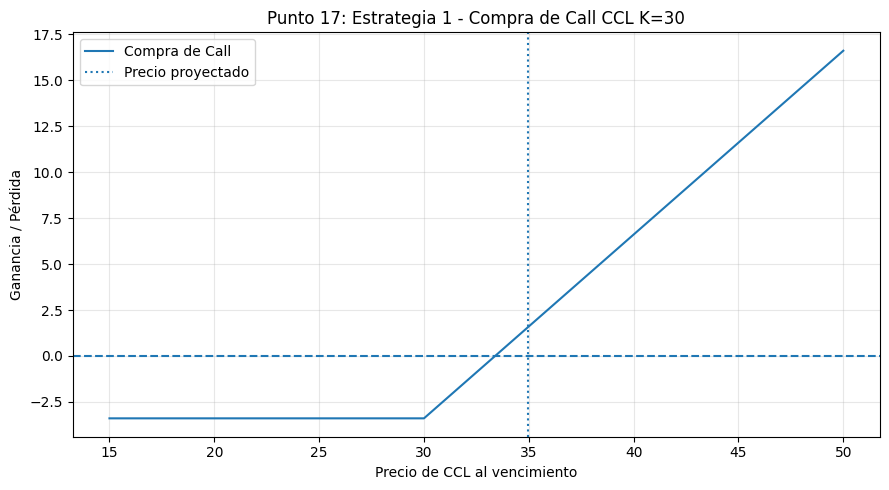

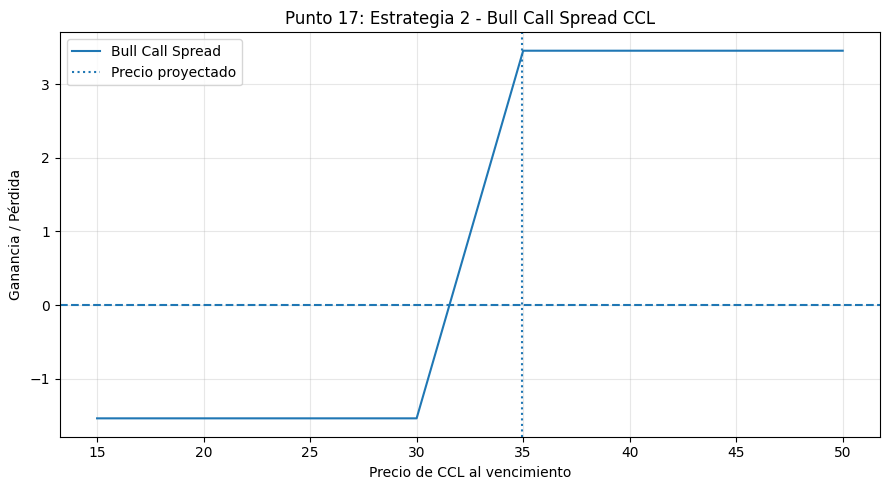

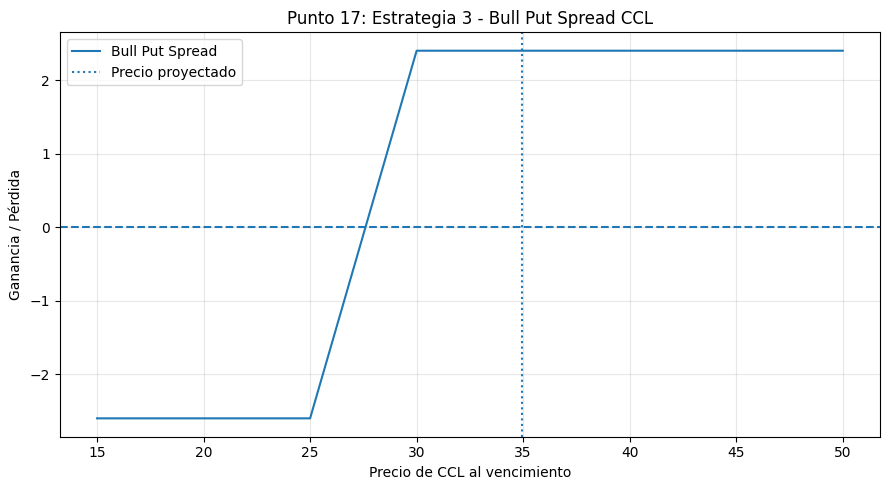

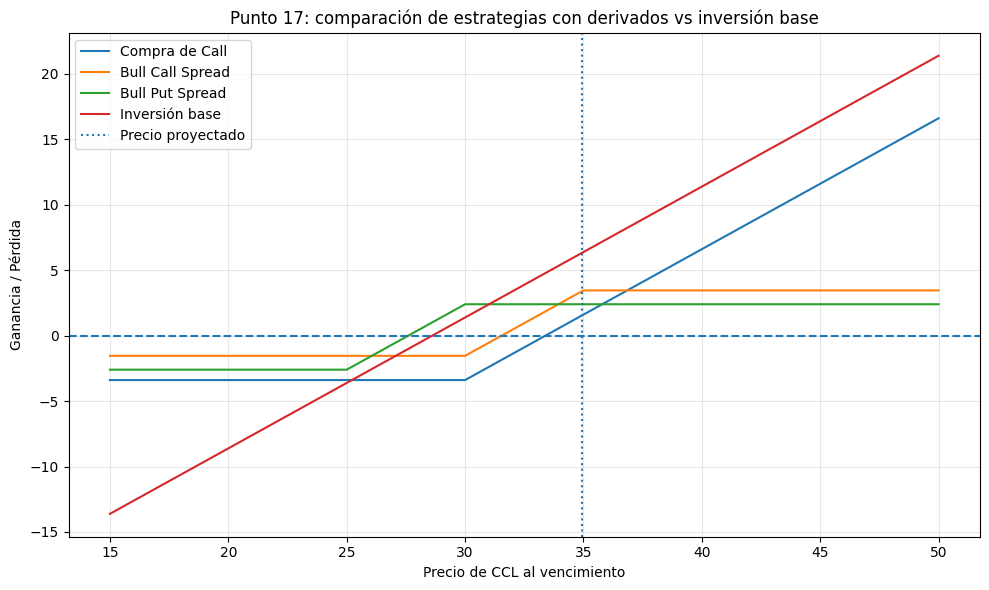

'salidas_examen3_equipo6/punto17_comparacion_estrategias.png'

In [ ]:
# ============================================================
# PUNTO 17. PROYECCIÓN Y ESTRATEGIAS CON DERIVADOS SOBRE CCL
# ============================================================

# Activo de mayor volatilidad: CCL
# Se usan datos del 17-jun-2024 al 17-ene-2026.
# Como 17-ene-2026 fue sábado, se utiliza el último día hábil anterior: 16-ene-2026.

ccl_17 = prices_15.loc["2024-06-17":"2026-01-16", "CCL"].dropna()
ccl_log_returns_17 = np.log(ccl_17 / ccl_17.shift(1)).dropna()

S0_ccl = ccl_17.iloc[-1]
mu_ccl = ccl_log_returns_17.mean()
sigma_ccl_daily = ccl_log_returns_17.std()
sigma_ccl_annual = sigma_ccl_daily * np.sqrt(252)

fecha_inicio_ccl = pd.Timestamp("2026-01-16")
fecha_final_ccl = pd.Timestamp("2026-07-17")
dias_bursatiles_ccl = len(pd.bdate_range(fecha_inicio_ccl, fecha_final_ccl)) - 1

precio_proyectado_ccl = S0_ccl * np.exp(mu_ccl * dias_bursatiles_ccl)

proyeccion_ccl_df = pd.DataFrame({
    "Concepto": [
        "Activo subyacente",
        "Precio inicial CCL",
        "Rendimiento promedio diario",
        "Volatilidad diaria",
        "Fecha inicio proyección",
        "Fecha final proyección",
        "Días bursátiles proyectados",
        "Precio proyectado CCL"
    ],
    "Valor": [
        "CCL",
        S0_ccl,
        mu_ccl,
        sigma_ccl_daily,
        fecha_inicio_ccl.strftime("%d/%m/%Y"),
        fecha_final_ccl.strftime("%d/%m/%Y"),
        dias_bursatiles_ccl,
        precio_proyectado_ccl
    ]
})

display(proyeccion_ccl_df)

# Estrategias con derivados:
# Escenario esperado: alcista
K1 = 30
K2 = 35
K0 = 25
T = dias_bursatiles_ccl / 252
r = risk_free_annual

def black_scholes_call(S, K, r, sigma, T):
    if T <= 0 or sigma <= 0:
        return max(S-K, 0)
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

def black_scholes_put(S, K, r, sigma, T):
    if T <= 0 or sigma <= 0:
        return max(K-S, 0)
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return K*np.exp(-r*T)*norm.cdf(-d2) - S*norm.cdf(-d1)

prima_call_30 = black_scholes_call(S0_ccl, K1, r, sigma_ccl_annual, T)
prima_call_35 = black_scholes_call(S0_ccl, K2, r, sigma_ccl_annual, T)
prima_put_30 = black_scholes_put(S0_ccl, K1, r, sigma_ccl_annual, T)
prima_put_25 = black_scholes_put(S0_ccl, K0, r, sigma_ccl_annual, T)

ganancia_long_call = max(precio_proyectado_ccl-K1, 0) - prima_call_30
ganancia_bull_call = max(precio_proyectado_ccl-K1, 0) - max(precio_proyectado_ccl-K2, 0) - (prima_call_30-prima_call_35)
ganancia_bull_put = (prima_put_30-prima_put_25) - max(K1-precio_proyectado_ccl, 0) + max(K0-precio_proyectado_ccl, 0)

estrategias_df = pd.DataFrame({
    "Estrategia": ["Compra de Call", "Bull Call Spread", "Bull Put Spread"],
    "Composición": [
        "Comprar Call K=30",
        "Comprar Call K=30 y vender Call K=35",
        "Vender Put K=30 y comprar Put K=25"
    ],
    "Costo / Crédito neto": [
        prima_call_30,
        prima_call_30 - prima_call_35,
        prima_put_30 - prima_put_25
    ],
    "Ganancia esperada": [
        ganancia_long_call,
        ganancia_bull_call,
        ganancia_bull_put
    ],
    "Justificación": [
        "Estrategia alcista; gana si CCL sube por encima de 30.",
        "Estrategia alcista moderada; limita costo y ganancia máxima.",
        "Estrategia alcista; gana si CCL se mantiene por encima de 30."
    ]
})

display(estrategias_df)

# Payoff para gráficas
precios_vencimiento = np.arange(15, 51, 1)
payoff_df = pd.DataFrame({
    "Precio CCL al vencimiento": precios_vencimiento
})
payoff_df["Compra de Call"] = np.maximum(payoff_df["Precio CCL al vencimiento"] - K1, 0) - prima_call_30
payoff_df["Bull Call Spread"] = (
    np.maximum(payoff_df["Precio CCL al vencimiento"] - K1, 0)
    - np.maximum(payoff_df["Precio CCL al vencimiento"] - K2, 0)
    - (prima_call_30 - prima_call_35)
)
payoff_df["Bull Put Spread"] = (
    (prima_put_30 - prima_put_25)
    - np.maximum(K1 - payoff_df["Precio CCL al vencimiento"], 0)
    + np.maximum(K0 - payoff_df["Precio CCL al vencimiento"], 0)
)
payoff_df["Inversión base"] = payoff_df["Precio CCL al vencimiento"] - S0_ccl

display(payoff_df.head())

# Gráficas individuales
for col, title in [
    ("Compra de Call", "Punto 17: Estrategia 1 - Compra de Call CCL K=30"),
    ("Bull Call Spread", "Punto 17: Estrategia 2 - Bull Call Spread CCL"),
    ("Bull Put Spread", "Punto 17: Estrategia 3 - Bull Put Spread CCL")
]:
    plt.figure(figsize=(9, 5))
    plt.plot(payoff_df["Precio CCL al vencimiento"], payoff_df[col], label=col)
    plt.axhline(0, linestyle="--")
    plt.axvline(precio_proyectado_ccl, linestyle=":", label="Precio proyectado")
    plt.title(title)
    plt.xlabel("Precio de CCL al vencimiento")
    plt.ylabel("Ganancia / Pérdida")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_plot(f"punto17_{col.replace(' ', '_').lower()}.png")

# Gráfica comparativa
plt.figure(figsize=(10, 6))
for col in ["Compra de Call", "Bull Call Spread", "Bull Put Spread", "Inversión base"]:
    plt.plot(payoff_df["Precio CCL al vencimiento"], payoff_df[col], label=col)
plt.axhline(0, linestyle="--")
plt.axvline(precio_proyectado_ccl, linestyle=":", label="Precio proyectado")
plt.title("Punto 17: comparación de estrategias con derivados vs inversión base")
plt.xlabel("Precio de CCL al vencimiento")
plt.ylabel("Ganancia / Pérdida")
plt.legend()
plt.grid(True, alpha=0.3)
save_plot("punto17_comparacion_estrategias.png")



In [6]:
# ============================================================
# EXPORTAR RESULTADOS A EXCEL
# ============================================================

import os
excel_path = os.path.join(OUTPUT_DIR, "Examen3_Equipo6_Resultados_Python.xlsx")

with pd.ExcelWriter(excel_path, engine="xlsxwriter") as writer:
    seleccion_empresas.to_excel(writer, sheet_name="02 Seleccion", index=False)
    prices_5y.to_excel(writer, sheet_name="Datos 2019-2024")
    returns_5y.to_excel(writer, sheet_name="Rend 2019-2024")
    volatilidades_p3.to_excel(writer, sheet_name="03 Volatilidades")
    portafolio.to_excel(writer, sheet_name="04 05 Portafolio", index=False)
    var_individual_diario.to_excel(writer, sheet_name="06 VaR individual")
    var_portafolio_df.to_excel(writer, sheet_name="07 VaR portafolio")
    betas_df.to_excel(writer, sheet_name="08 09 Betas")
    criterios_p10.to_excel(writer, sheet_name="10 Criterios MA", index=False)
    criterios_p11.to_excel(writer, sheet_name="11 Criterios MACD RSI", index=False)
    for t in tickers:
        macd_rsi_data[t].to_excel(writer, sheet_name=f"11 MACD RSI {t}")
    mercado_resumen.to_excel(writer, sheet_name="12 Proy mercado", index=False)
    sp500_projection.to_excel(writer, sheet_name="12 SP500 proyeccion")
    capm_df.to_excel(writer, sheet_name="13 CAPM", index=False)
    fecha_base_2026_df.to_excel(writer, sheet_name="14 Fecha base", index=False)
    signals_15.to_excel(writer, sheet_name="15 Señales")
    bitacora_df.to_excel(writer, sheet_name="15 Bitacora", index=False)
    ordenes_resumen.to_excel(writer, sheet_name="15 Resumen ordenes")
    positions.to_excel(writer, sheet_name="16 Posiciones")
    pd.DataFrame({
        "Rendimiento real portafolio": portfolio_real_returns,
        "Valor portafolio": portfolio_value_real
    }).to_excel(writer, sheet_name="16 Valor real")
    comparacion_p16.to_excel(writer, sheet_name="16 Comparacion", index=False)
    proyeccion_ccl_df.to_excel(writer, sheet_name="17 Proy CCL", index=False)
    estrategias_df.to_excel(writer, sheet_name="17 Estrategias", index=False)
    payoff_df.to_excel(writer, sheet_name="17 Payoffs", index=False)

print("Excel exportado:", excel_path)

NameError: name 'OUTPUT_DIR' is not defined

In [ ]:
# ============================================================
# CREAR ZIP CON EXCEL Y GRÁFICAS
# ============================================================

zip_path = "Examen3_Equipo6_Resultados_Python.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    # Agregar excel
    z.write(excel_path, arcname=os.path.basename(excel_path))

    # Agregar imágenes png
    for file in os.listdir(OUTPUT_DIR):
        if file.endswith(".png"):
            z.write(os.path.join(OUTPUT_DIR, file), arcname=file)

print("ZIP generado:", zip_path)

# Descargar en Google Colab
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Si no estás en Colab, el archivo ZIP quedó guardado en:", zip_path)



ZIP generado: Examen3_Equipo6_Resultados_Python.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>